# Notebook 05: Embedding Preparation

## Introduction

This notebook focuses on preparing and generating text embeddings from the final metadata dataset.

The embeddings represent the textual information associated with each image, including its captions and object categories.

The generated embeddings will be saved and organized for future retrieval operations.

This notebook is part of Phase 1: Data Exploration and Preprocessing.

In [1]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(r"C:\Users\PC\Desktop\Metadata_RAG_START")
DATA_DIR = PROJECT_DIR / "data"
EMBEDDINGS_DIR = PROJECT_DIR / "embeddings"

METADATA_PATH = DATA_DIR / "metadata.csv"

metadata_df = pd.read_csv(METADATA_PATH)

print("Metadata loaded successfully!")
print("Dataset shape:", metadata_df.shape)

display(metadata_df.head())

Metadata loaded successfully!
Dataset shape: (10099, 14)


,image_id,file_name,dataset,processed_path,width,height,original_mode,processed_mode,original_captions,cleaned_captions,caption_count,objects,object_count,object_categories
0,36,000000000036.jpg,training,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,481,640,RGB,RGB,['Woman in swim suit holding parasol on sunny ...,['Woman in swim suit holding parasol on sunny ...,5,"[{'category': 'umbrella', 'category_id': 28, '...",2,"['person', 'umbrella']"
1,73,000000000073.jpg,training,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,565,640,RGB,RGB,['A motorcycle parked in a parking space next ...,['A motorcycle parked in a parking space next ...,5,"[{'category': 'motorcycle', 'category_id': 4, ...",2,['motorcycle']
2,89,000000000089.jpg,training,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,640,480,RGB,RGB,['An oven with a stove on top of it in a kitch...,['An oven with a stove on top of it in a kitch...,5,"[{'category': 'knife', 'category_id': 49, 'bbo...",10,"['book', 'knife', 'microwave', 'oven']"
3,109,000000000109.jpg,training,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,640,416,RGB,RGB,['A skate park next to a body of water and gre...,['A skate park next to a body of water and gre...,5,"[{'category': 'dog', 'category_id': 18, 'bbox'...",8,"['bench', 'dog', 'person']"
4,196,000000000196.jpg,training,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,640,480,RGB,RGB,['This table is filled with a variety of diffe...,['This table is filled with a variety of diffe...,5,"[{'category': 'spoon', 'category_id': 50, 'bbo...",42,"['bowl', 'broccoli', 'carrot', 'dining table',..."


## Step 3: Prepare Text for Embedding

This step prepares a textual representation for each image.

The text combines the cleaned captions and object categories associated with each image.

This representation provides descriptive information about the image and will be used as input for the embedding model.

### 3.1 Create Text Descriptions

For each image, the five cleaned captions and the detected object categories are combined into a single text description.

This creates one textual document per image while preserving its image ID.

In [2]:
import ast

def prepare_image_text(row):
    captions = row["cleaned_captions"]
    categories = row["object_categories"]

    # Convert string representations of lists into Python lists
    if isinstance(captions, str):
        captions = ast.literal_eval(captions)

    if isinstance(categories, str):
        categories = ast.literal_eval(categories)

    captions_text = " ".join(captions)
    objects_text = ", ".join(categories)

    return (
        f"Captions: {captions_text} "
        f"Objects: {objects_text}"
    )


metadata_df["embedding_text"] = metadata_df.apply(
    prepare_image_text,
    axis=1
)

print("Text preparation completed!")
print("Total text descriptions:", len(metadata_df))
display(metadata_df[["image_id", "embedding_text"]].head())

Text preparation completed!
Total text descriptions: 10099


,image_id,embedding_text
0,36,Captions: Woman in swim suit holding parasol o...
1,73,Captions: A motorcycle parked in a parking spa...
2,89,Captions: An oven with a stove on top of it in...
3,109,Captions: A skate park next to a body of water...
4,196,Captions: This table is filled with a variety ...


### 3.2 Verify Prepared Text

This step checks the generated textual descriptions.

It verifies that no descriptions are missing or empty and displays an example for inspection.

In [4]:
print("Total descriptions:", len(metadata_df))

print(
    "Missing descriptions:",
    metadata_df["embedding_text"].isna().sum()
)

print(
    "Empty descriptions:",
    (metadata_df["embedding_text"].str.strip() == "").sum()
)

print("\nExample description:")
print(metadata_df.loc[0, "embedding_text"])

Total descriptions: 10099
Missing descriptions: 0
Empty descriptions: 0

Example description:
Captions: Woman in swim suit holding parasol on sunny day. A woman posing for the camera, holding a pink, open umbrella and wearing a bright, floral, ruched bathing suit, by a life guard stand with lake, green trees, and a blue sky with a few clouds behind. A woman in a floral swimsuit holds a pink umbrella. A woman with an umbrella near the sea A girl in a bathing suit with a pink umbrella. Objects: person, umbrella


## Step 4: Load the Embedding Model

This step prepares the Sentence Transformers library and loads a pre-trained text embedding model.

The selected model converts textual descriptions into numerical vector representations.

### 4.1 Install Sentence Transformers

The Sentence Transformers library is required to load the selected pre-trained embedding model.

In [5]:
%pip install -U sentence-transformers

   ---------------------------------------- 0.0/760.7 kB ? eta -:--:--
   ---------------------------------------- 0.0/760.7 kB ? eta -:--:--
   ---------------------------------------- 0.0/760.7 kB ? eta -:--:--
   ------------- -------------------------- 262.1/760.7 kB ? eta -:--:--
   ------------- -------------------------- 262.1/760.7 kB ? eta -:--:--
   -------------------------- ----------- 524.3/760.7 kB 885.6 kB/s eta 0:00:01
   ---------------------------------------- 760.7/760.7 kB 968.1 kB/s  0:00:01
   ---------------------------------------- 0.0/857.0 kB ? eta -:--:--
   ------------ --------------------------- 262.1/857.0 kB ? eta -:--:--
   ------------------------ --------------- 524.3/857.0 kB 1.4 MB/s eta 0:00:01
   ---------------------------------------- 857.0/857.0 kB 1.5 MB/s  0:00:00
   ---------------------------------------- 0.0/3.9 MB ? eta -:--:--
   -- ------------------------------------- 0.3/3.9 MB ? eta -:--:--
   -------- -------------------------------

### 4.2 Load the Pre-trained Model

The all-MiniLM-L6-v2 model is loaded to generate 384-dimensional embeddings from the prepared image descriptions.

In [6]:
from sentence_transformers import SentenceTransformer

MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"

model = SentenceTransformer(MODEL_NAME)

print("Model loaded successfully!")
print("Model name:", MODEL_NAME)
print("Embedding dimension:", model.get_sentence_embedding_dimension())

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

c:\Users\PC\anaconda3\envs\metadata_rag\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\PC\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (7 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Model loaded successfully!
Model name: sentence-transformers/all-MiniLM-L6-v2
Embedding dimension: 384


C:\Users\PC\anaconda3\tmp\ipykernel_21064\2592934743.py:9: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print("Embedding dimension:", model.get_sentence_embedding_dimension())


## Step 5: Generate Text Embeddings

This step converts the prepared textual description of each image into a numerical embedding using the pre-trained Sentence Transformers model.

Each image will be represented by a 384-dimensional vector. The image IDs will be preserved to maintain the association between each embedding and its corresponding image.

In [7]:
# Generate one embedding for each image description

texts = metadata_df["embedding_text"].tolist()

embeddings = model.encode(
    texts,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

print("Embedding generation completed!")
print("Number of embeddings:", embeddings.shape[0])
print("Embedding dimension:", embeddings.shape[1])
print("Total images:", len(metadata_df))

Batches:   0%|          | 0/316 [00:00<?, ?it/s]

Embedding generation completed!
Number of embeddings: 10099
Embedding dimension: 384
Total images: 10099


## Step 6: Save the Generated Embeddings

This step saves the generated embeddings to disk for future use.

The embeddings are stored in NumPy format, while a separate CSV file preserves the association between each image ID and its corresponding vector index.

This ensures that the embeddings can be reloaded without generating them again.

In [8]:
import numpy as np
import pandas as pd

# Create the embeddings directory if it does not exist
EMBEDDINGS_DIR.mkdir(parents=True, exist_ok=True)

# Save the numerical embeddings
EMBEDDINGS_PATH = EMBEDDINGS_DIR / "image_embeddings.npy"

np.save(EMBEDDINGS_PATH, embeddings)

# Save the mapping between image IDs and embedding indices
embedding_index_df = metadata_df[["image_id", "file_name", "dataset"]].copy()
embedding_index_df["embedding_index"] = range(len(embedding_index_df))

INDEX_PATH = EMBEDDINGS_DIR / "embedding_index.csv"
embedding_index_df.to_csv(INDEX_PATH, index=False)

print("Embeddings saved successfully!")
print("Embeddings file:", EMBEDDINGS_PATH)
print("Index file:", INDEX_PATH)
print("Embedding shape:", np.load(EMBEDDINGS_PATH, mmap_mode="r").shape)
print("Index records:", len(embedding_index_df))

Embeddings saved successfully!
Embeddings file: C:\Users\PC\Desktop\Metadata_RAG_START\embeddings\image_embeddings.npy
Index file: C:\Users\PC\Desktop\Metadata_RAG_START\embeddings\embedding_index.csv
Embedding shape: (10099, 384)
Index records: 10099


## Step 7: Verify the Saved Embeddings

This step verifies that the saved embeddings and their index can be reloaded correctly.

It checks the embedding dimensions, the number of records, the uniqueness of image IDs, and the presence of invalid numerical values.

In [9]:
import numpy as np
import pandas as pd

# Reload the saved files
saved_embeddings = np.load(EMBEDDINGS_PATH)
saved_index = pd.read_csv(INDEX_PATH)

# Verify the saved data
print("Embeddings shape:", saved_embeddings.shape)
print("Index records:", len(saved_index))
print("Unique image IDs:", saved_index["image_id"].nunique())
print("Missing values in index:", saved_index.isna().sum().sum())
print("NaN values in embeddings:", np.isnan(saved_embeddings).sum())
print("Infinite values in embeddings:", np.isinf(saved_embeddings).sum())

# Verify alignment between metadata and index
print(
    "Image IDs aligned:",
    metadata_df["image_id"].reset_index(drop=True).equals(
        saved_index["image_id"].reset_index(drop=True)
    )
)

# Verify embedding normalization
norms = np.linalg.norm(saved_embeddings, axis=1)
print("All embeddings normalized:", np.allclose(norms, 1.0, atol=1e-5))

Embeddings shape: (10099, 384)
Index records: 10099
Unique image IDs: 10099
Missing values in index: 0
NaN values in embeddings: 0
Infinite values in embeddings: 0
Image IDs aligned: True
All embeddings normalized: True


### Step 8: Inspect the Saved Embeddings

This step displays a small sample of the saved numerical embeddings to confirm that the file contains valid vector representations.

In [10]:
import numpy as np

# Load the saved embeddings
saved_embeddings = np.load(EMBEDDINGS_PATH)

# Display the first embedding
print("Embedding shape:", saved_embeddings.shape)
print("\nFirst 10 values of the first embedding:")
print(saved_embeddings[0][:10])

# Display the corresponding image ID
print("\nCorresponding image ID:")
print(embedding_index_df.iloc[0]["image_id"])

Embedding shape: (10099, 384)

First 10 values of the first embedding:
[-0.01507843  0.07417449  0.0561268   0.02540457  0.1162094  -0.00146455
  0.1318551  -0.04248518 -0.02420656  0.00747124]

Corresponding image ID:
36


In [1]:
import numpy as np
import pandas as pd

# Load the numbers
embeddings = np.load("../data/embeddings/embeddings/image_embeddings.npy")

# Show the first 5 rows and first 10 numbers as a table
pd.DataFrame(embeddings[:5, :10])

,0,1,2,3,4,5,6,7,8,9
0,-0.015078,0.074174,0.056127,0.025405,0.116209,-0.001465,0.131855,-0.042485,-0.024207,0.007471
1,-0.007085,0.059378,-0.057463,-0.076627,0.055441,-0.015654,0.077708,0.026217,0.092527,-0.014986
2,-0.010772,0.077536,-0.061432,0.008891,-0.002653,-0.041795,0.051260,-0.060205,0.047334,0.026093
3,0.009478,-0.022592,0.035324,-0.010547,0.019793,0.038003,0.080542,-0.015828,0.018619,0.015438
4,0.026150,-0.039390,0.002575,0.007029,-0.049675,0.037130,0.021195,-0.085475,0.007694,-0.007864


In [4]:
import numpy as np
import pandas as pd
import os

# This gets the exact current folder of the notebook
current_dir = os.getcwd()

# This goes up one level (out of 'notebooks') and points to the file
file_path = os.path.join(current_dir, "..", "data", "embeddings", "embeddings", "image_embeddings.npy")

# Load it
embeddings = np.load(file_path)

print("Success! Shape:", embeddings.shape)

Success! Shape: (10099, 384)


Row 0 matches this image file: 000000000036.jpg


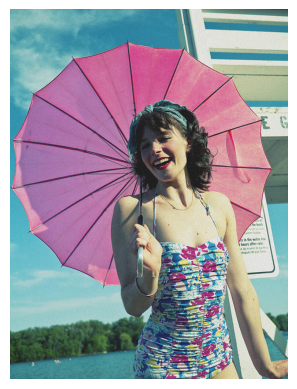

In [5]:
import matplotlib.pyplot as plt
from PIL import Image
import os
import pandas as pd

# 1. Load the index map
index_df = pd.read_csv("../data/embeddings/embeddings/embedding_index.csv")

# 2. Get the file name for the first image (row 0)
first_image_name = index_df.iloc[0]['file_name']
print(f"Row 0 matches this image file: {first_image_name}")

# 3. Point to where the actual images are stored
# (Check your VS Code sidebar to make sure this folder path is exactly right)
image_path = os.path.join("..", "_tmp_extract", "shared_dataset", "train_images", first_image_name)

# 4. Display the image
if os.path.exists(image_path):
    img = Image.open(image_path)
    plt.imshow(img)
    plt.axis('off')
    plt.show()
else:
    print(f"Could not find the image at {image_path}. Check the folder path!")

# Conclusion

This notebook completed the embedding preparation stage of Phase 1.

The final metadata dataset was used to create one textual description for each image by combining its cleaned captions and object categories.

The pre-trained Sentence Transformers model, `all-MiniLM-L6-v2`, generated 10,099 embeddings, each represented by a 384-dimensional vector.

The embeddings were saved in NumPy format in `embeddings/image_embeddings.npy`. A separate index file, `embeddings/embedding_index.csv`, was created to preserve the association between each image and its corresponding embedding.

Final verification confirmed that all 10,099 image IDs are unique and correctly aligned with the embeddings. No missing index values, NaN values, or infinite values were detected. All embeddings were successfully normalized.

Therefore, the embedding preparation stage is complete. The generated embeddings are saved and ready for use in the future retrieval stage.

This concludes Notebook 05 and completes the embedding preparation component of Phase 1.